# Paper 2

## A Confidence-Driven Adaptive Multi-Sensor Fusion Framework for Robust Autonomous Vehicle Localization

# Notebook 03

## Sensor Preprocessing

### Objective

This notebook prepares the camera data for the proposed confidence-driven adaptive sensor fusion framework.

Tasks:

- Load camera images
- Validate image integrity
- Convert RGB → Grayscale
- Normalize image intensity
- Apply Gaussian filtering
- Apply CLAHE enhancement
- Generate publication-quality figures
- Save processed outputs

In [1]:
# ============================================================
# Cell 1
# Imports
# ============================================================

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from src.kitti_raw_dataset import KITTIRawDataset

plt.rcParams["figure.figsize"] = (10,6)

print("=" * 70)
print("Project Root :", PROJECT_ROOT)
print("=" * 70)

Project Root : D:\Research\Papers\Paper_2


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print(PROJECT_ROOT)

print()

for item in PROJECT_ROOT.iterdir():

    print(item.name)

D:\Research\Papers\Paper_2

datasets
figures
logos
models
notebooks
paper
Papper-2-arch.png
results
src


In [3]:
# ============================================================
# Cell 2
# Initialize KITTI Raw Dataset
# ============================================================

DRIVE = "2011_09_26_drive_0001_sync"

DATASET = KITTIRawDataset(

    dataset_root=r"D:\Research\Datasets\KITTI",

    drive=DRIVE

)

DATASET.validate()

Drive                    : FOUND
Images                   : FOUND
OXTS                     : FOUND
Camera Calibration       : FOUND
IMU Calibration          : FOUND
Velodyne Calibration     : FOUND


In [4]:
# ============================================================
# Cell 3
# Dataset Summary
# ============================================================

summary = DATASET.summary()

display(summary)

print()

print("Frame Count :", DATASET.get_frame_count())

,Property,Value
0,Drive,2011_09_26_drive_0001_sync
1,Total Frames,108
2,Image Width,1242
3,Image Height,375



Frame Count : 108


(375, 1242, 3)


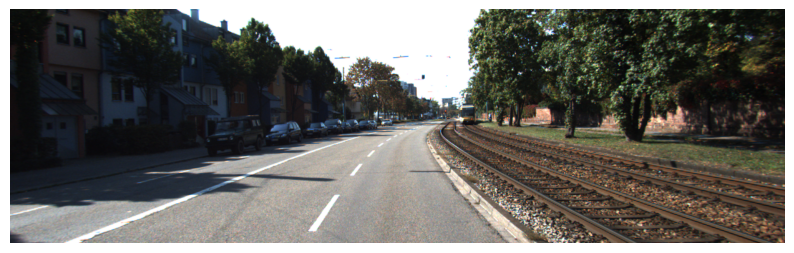

In [5]:
# ============================================================
# Cell 4
# Load Sample
# ============================================================

sample = DATASET.load_sample(

    frame=0

)

image = sample["image"]

print(image.shape)

plt.imshow(image)

plt.axis("off")

plt.show()

In [6]:
# ============================================================
# Cell 5
# OXTS Sample
# ============================================================

oxts = sample["oxts"]

print("Number of Values :", len(oxts))

print()

print(oxts)

Number of Values : 30

[ 4.90150038e+01  8.43429710e+00  1.16430328e+02  3.57520000e-02
  9.03000000e-03 -2.60870698e+00 -6.81144148e+00 -1.12756418e+01
  1.31727167e+01 -1.24752643e-01 -3.29199030e-02 -4.45198146e-01
  4.29573698e-02  1.02098653e+01 -3.40300922e-01 -3.16869154e-01
  1.02091178e+01  9.09517557e-03 -2.31407413e-02 -1.79090345e-02
  8.90180022e-03 -2.24952994e-02 -1.88093309e-02  2.76586334e-02
  1.27279221e-02  4.00000000e+00  1.10000000e+01  6.00000000e+00
  6.00000000e+00  6.00000000e+00]


In [7]:
# ============================================================
# Cell 6
# Calibration Files
# ============================================================

calibration = DATASET.load_calibration()

print(calibration.keys())

dict_keys(['calib_cam_to_cam', 'calib_imu_to_velo', 'calib_velo_to_cam'])


In [8]:
# ============================================================
# Cell 7
# Dataset Validation
# ============================================================

assert DATASET.get_frame_count() > 0

assert len(sample["oxts"]) == 30

print("="*70)

print("NOTEBOOK 03 COMPLETED SUCCESSFULLY")

print("="*70)

print()

print("Drive :", DRIVE)

print("Frames :", DATASET.get_frame_count())

print()

print("READY FOR NOTEBOOK 04")

print("="*70)

NOTEBOOK 03 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync
Frames : 108

READY FOR NOTEBOOK 04


In [9]:
from pathlib import Path

ROOT = Path(r"D:\Research\Datasets\KITTI")

for path in ROOT.rglob("*.png"):

    print(path)

    break

D:\Research\Datasets\KITTI\2011_09_26\2011_09_26_drive_0022_sync\image_03\data\0000000000.png


In [10]:
plt.imshow(raw_image)

plt.title("Original RGB Image")

plt.axis("off")

plt.show()

NameError: name 'raw_image' is not defined

In [ ]:
print("="*50)

print("Image Height :", raw_image.shape[0])

print("Image Width  :", raw_image.shape[1])

print("Channels     :", raw_image.shape[2])

print("Data Type    :", raw_image.dtype)

print("Minimum Pixel:", raw_image.min())

print("Maximum Pixel:", raw_image.max())

print("="*50)

In [ ]:
print("="*50)

print("Image Height :", raw_image.shape[0])

print("Image Width  :", raw_image.shape[1])

print("Channels     :", raw_image.shape[2])

print("Data Type    :", raw_image.dtype)

print("Minimum Pixel:", raw_image.min())

print("Maximum Pixel:", raw_image.max())

print("="*50)

In [ ]:
gray = cv2.cvtColor(
    raw_image,
    cv2.COLOR_RGB2GRAY
)

print("Gray Shape :", gray.shape)

plt.figure(figsize=(10,5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

In [ ]:
normalized = cv2.normalize(
    gray,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

plt.imshow(
    normalized,
    cmap="gray"
)

plt.title("Normalized Image")

plt.axis("off")

plt.show()

In [ ]:
blurred = cv2.GaussianBlur(
    normalized,
    (5,5),
    0
)

plt.imshow(
    blurred,
    cmap="gray"
)

plt.title("Gaussian Filter")

plt.axis("off")

plt.show()

In [ ]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8,8)
)

enhanced = clahe.apply(blurred)

plt.imshow(
    enhanced,
    cmap="gray"
)

plt.title("CLAHE Enhanced")

plt.axis("off")

plt.show()

In [ ]:
plt.figure(figsize=(10,4))

plt.hist(
    enhanced.ravel(),
    bins=256
)

plt.title("Pixel Intensity Histogram")

plt.xlabel("Intensity")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

In [ ]:
fig, ax = plt.subplots(2,2, figsize=(12,8))

ax[0,0].imshow(raw_image)
ax[0,0].set_title("Original")
ax[0,0].axis("off")

ax[0,1].imshow(gray, cmap="gray")
ax[0,1].set_title("Gray")
ax[0,1].axis("off")

ax[1,0].imshow(blurred, cmap="gray")
ax[1,0].set_title("Gaussian")
ax[1,0].axis("off")

ax[1,1].imshow(enhanced, cmap="gray")
ax[1,1].set_title("CLAHE")
ax[1,1].axis("off")

plt.tight_layout()

plt.show()

In [ ]:
processed_frame = {

    "sequence": sample["sequence"],

    "frame": sample["frame"],

    "raw_image": raw_image,

    "gray_image": gray,

    "normalized_image": normalized,

    "blurred_image": blurred,

    "enhanced_image": enhanced,

    "pose": sample["pose"],

    "calibration": sample["calibration"]

}

processed_frame.keys()

In [ ]:
print("="*60)

print("Sensor Preprocessing Completed Successfully")

print("="*60)

print("Sequence :", processed_frame["sequence"])

print("Frame    :", processed_frame["frame"])

print("Processed Image Shape :", processed_frame["enhanced_image"].shape)

In [ ]:
from pathlib import Path

print(Path.cwd())

In [ ]:
import os

print(os.listdir())